# Exploratory Data Analysis: Sentinel-2 Water Extraction & Water Quality Inversion

This notebook explores the cleaned, matched datasets linking **Sentinel-2 Surface Reflectance (BOA)** with in-situ **USGS Continuous Water Quality Measurements** across 5 river basins:
- Delaware River Basin
- Illinois River Basin
- Trinity River Basin
- Upper Colorado River Basin
- Willamette River Basin

We investigate:
1. Water quality target distributions (Raw vs $\log_{10}$ transformed)
2. Multi-spectral signatures across water quality regimes
3. Cross-basin sample distribution and spatial gauge distribution
4. Disagreement between Deep Learning water masking and naive $\text{NDWI} > 0$ thresholding

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.1)
%matplotlib inline

# Resolve dataset path whether running from notebooks/ or repository root
if os.path.exists(os.path.join("..", "data", "processed", "matched_wq_cleaned")):
    DATA_DIR = os.path.join("..", "data", "processed", "matched_wq_cleaned")
    RESULTS_DIR = os.path.join("..", "results")
else:
    DATA_DIR = os.path.join("data", "processed", "matched_wq_cleaned")
    RESULTS_DIR = os.path.join("results")

print(f"Data directory: {os.path.abspath(DATA_DIR)}")

Data directory: C:\Term Paper 2\satellite-water-monitoring-ai\data\processed\matched_wq_cleaned


## 1. Load Processed Datasets

We load Dataset (b) [DL-Masked] containing observations verified by the deep learning water classification front-end.

In [2]:
dl_data_path = os.path.join(DATA_DIR, "matched_set_b_dl_masked.csv")
df_dl = pd.read_csv(dl_data_path)
print(f"Loaded {len(df_dl):,} records from {dl_data_path}")
display(df_dl.head())

Loaded 51,197 records from data\processed\matched_wq_cleaned\matched_set_b_dl_masked.csv


,scene,scene_datetime_UTC,sample_datetime_UTC,site_no,station_nm,parm_cd,parm_nm,parm_unit,Lat,Long,...,ndwi,mndwi,ndci,turbidity_ratio,cdom_ratio,b8_b4_ratio,year,water_mask_ndwi,dl_water_prob,water_mask_dl
0,S2B_MSIAQR_20230727T164849_N0509_R026_T15SXD_2...,2023-07-27 16:48:49+00:00,2023-07-27 12:45:00+00:00,5586300,"ILLINOIS RIVER AT FLORENCE, IL",32316,"Chlorophyll fluorescence (fChl), water, in sit...",ug/l,39.632750,-90.607667,...,-0.132393,-0.040498,-0.039049,0.993490,0.719144,1.313704,2023,0,0.845936,1
1,S2A_MSIAQR_20230612T164841_N0509_R026_T15RTP_2...,2023-06-12 16:48:41+00:00,2023-06-12 06:00:00+00:00,295554095093402,"Lk Hou at Jack's Ditch (Site 2) nr Houston, TX",63680,"Turbidity, water, unfiltered, monochrome near ...",FNU,29.938250,-95.166778,...,0.662252,-0.381743,0.601891,0.799975,0.726961,0.253958,2023,1,0.985871,1
2,S2A_MSIAQR_20230314T165051_N0509_R026_T15RUN_2...,2023-03-14 16:50:51+00:00,2023-03-14 14:00:00+00:00,294643095035200,"Lynchburg Res nr CWA Canal Inflow nr Baytown, TX",32316,"Chlorophyll fluorescence (fChl), water, in sit...",ug/l,29.778586,-95.064428,...,0.854310,-0.226171,0.240751,0.778951,0.572562,0.100853,2023,1,0.997863,1
3,S2B_MSIAQR_20240419T163839_N0510_R126_T16TCL_2...,2024-04-19 16:38:39+00:00,2024-04-19 09:00:00+00:00,5543010,"ILLINOIS RIVER AT SENECA, IL",63680,"Turbidity, water, unfiltered, monochrome near ...",FNU,41.299889,-88.614194,...,0.012379,0.036619,0.069828,0.959213,0.706503,1.016968,2024,1,0.987166,1
4,S2A_MSIAQR_20221008T170211_N0400_R069_T15RTP_2...,2022-10-08 17:02:11+00:00,2022-10-08 17:30:00+00:00,294643095035200,"Lynchburg Res nr CWA Canal Inflow nr Baytown, TX",63680,"Turbidity, water, unfiltered, monochrome near ...",FNU,29.778586,-95.064428,...,0.912010,-0.335709,0.376852,0.644162,0.595083,0.071427,2022,1,0.997028,1


## 2. In-Situ Water Quality Distributions

Water quality parameters span multiple orders of magnitude due to storm runoff and seasonal phytoplankton blooms. Standard machine learning models suffer from severe heteroscedasticity without logarithmic transformation.

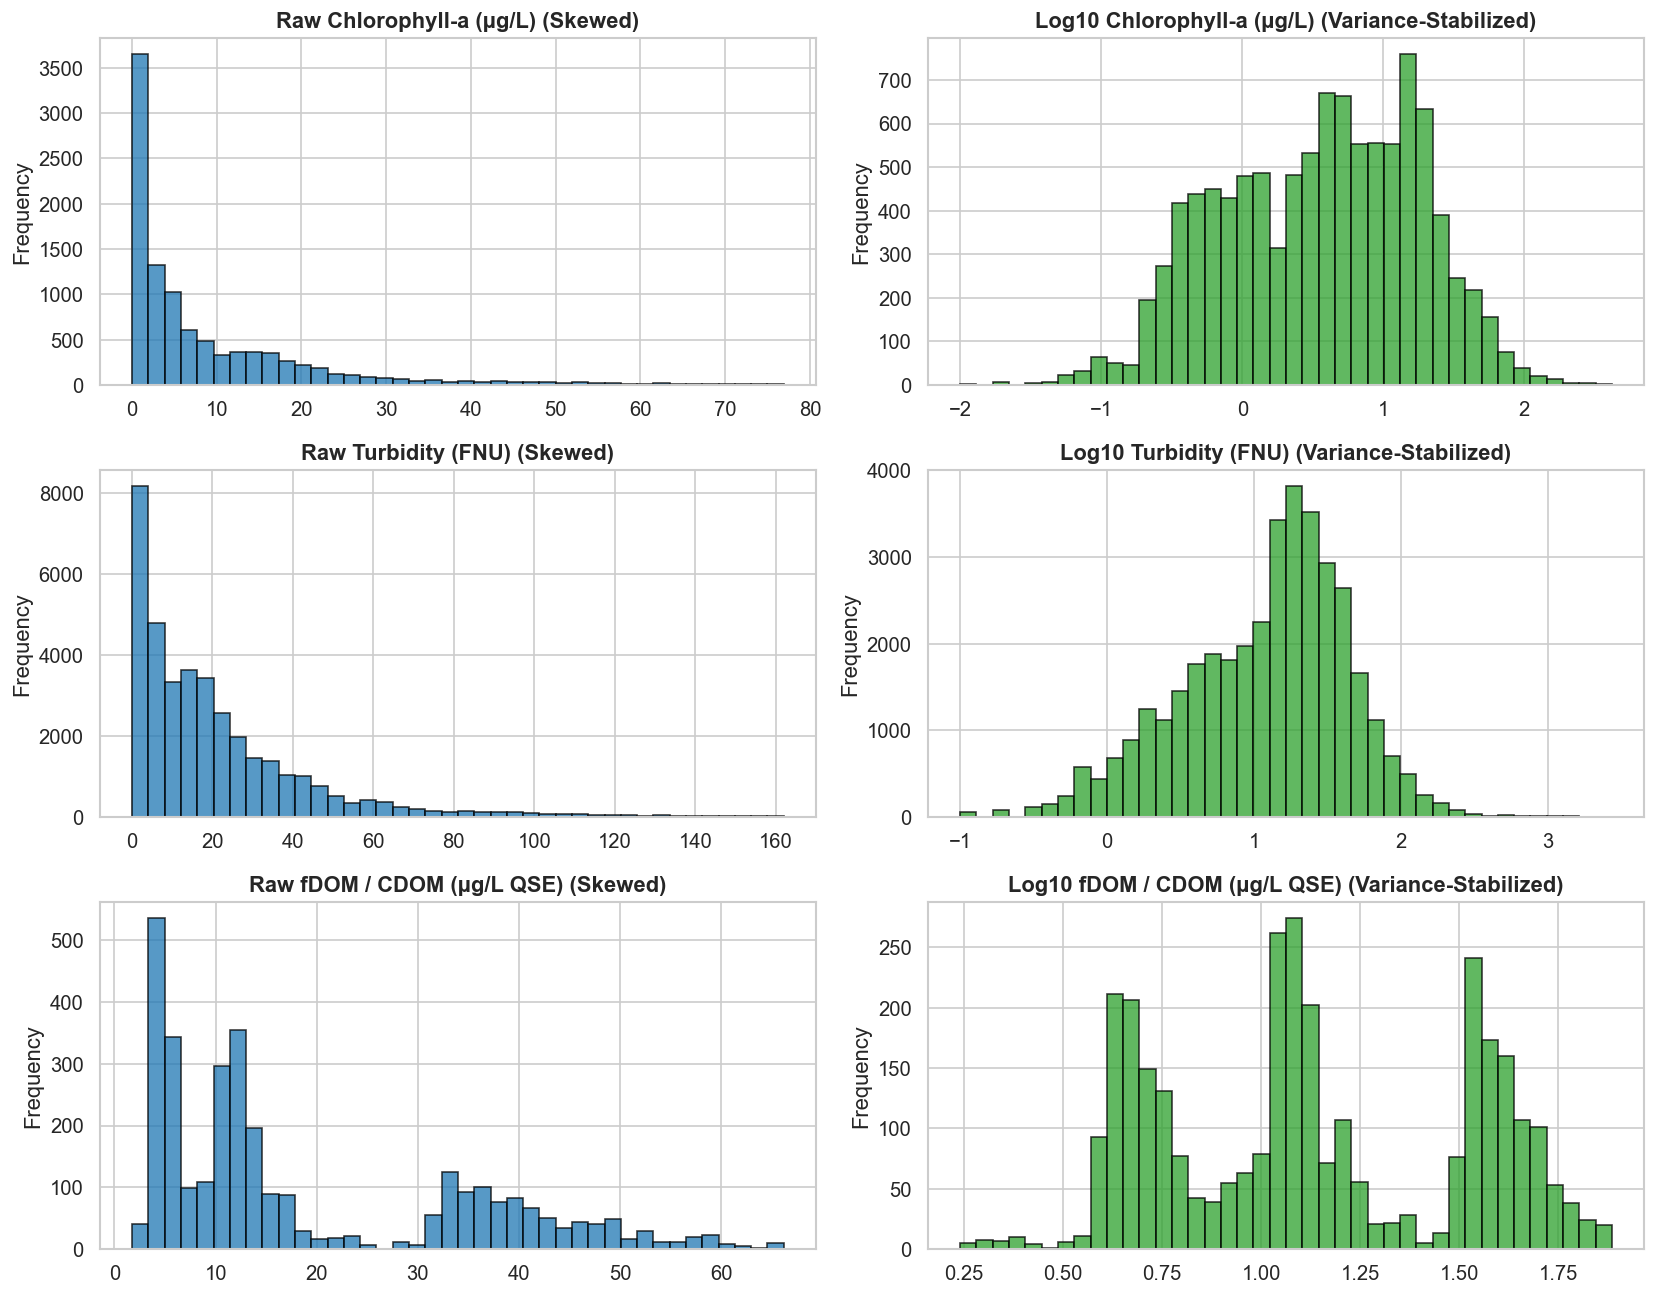

In [3]:
targets = [
    ('chlorophyll', 'Chlorophyll-a (μg/L)'),
    ('turbidity', 'Turbidity (FNU)'),
    ('cdom', 'fDOM / CDOM (μg/L QSE)')
]

fig, axes = plt.subplots(3, 2, figsize=(14, 11), dpi=120)

for row_idx, (t_name, label) in enumerate(targets):
    sub = df_dl[df_dl['target_type'] == t_name]['MeasurementValue'].dropna()
    sub_pos = sub[sub > 0]
    
    # Raw (99th percentile cutoff for readable histogram)
    p99 = np.percentile(sub_pos, 99)
    axes[row_idx, 0].hist(sub_pos[sub_pos <= p99], bins=40, color='#1f77b4', edgecolor='black', alpha=0.75)
    axes[row_idx, 0].set_title(f"Raw {label} (Skewed)", fontweight='bold')
    axes[row_idx, 0].set_ylabel('Frequency')
    
    # Log10-transformed
    log_vals = np.log10(sub_pos)
    axes[row_idx, 1].hist(log_vals, bins=40, color='#2ca02c', edgecolor='black', alpha=0.75)
    axes[row_idx, 1].set_title(f"Log10 {label} (Variance-Stabilized)", fontweight='bold')
    axes[row_idx, 1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

## 3. Spectral Signatures Across Turbidity Regimes

We examine Sentinel-2 Bottom-Of-Atmosphere (BOA) surface reflectances across three turbidity tiers:
- **Clear Water** (< 5 FNU)
- **Moderate Turbidity** (5–25 FNU)
- **High Turbidity** (> 25 FNU)

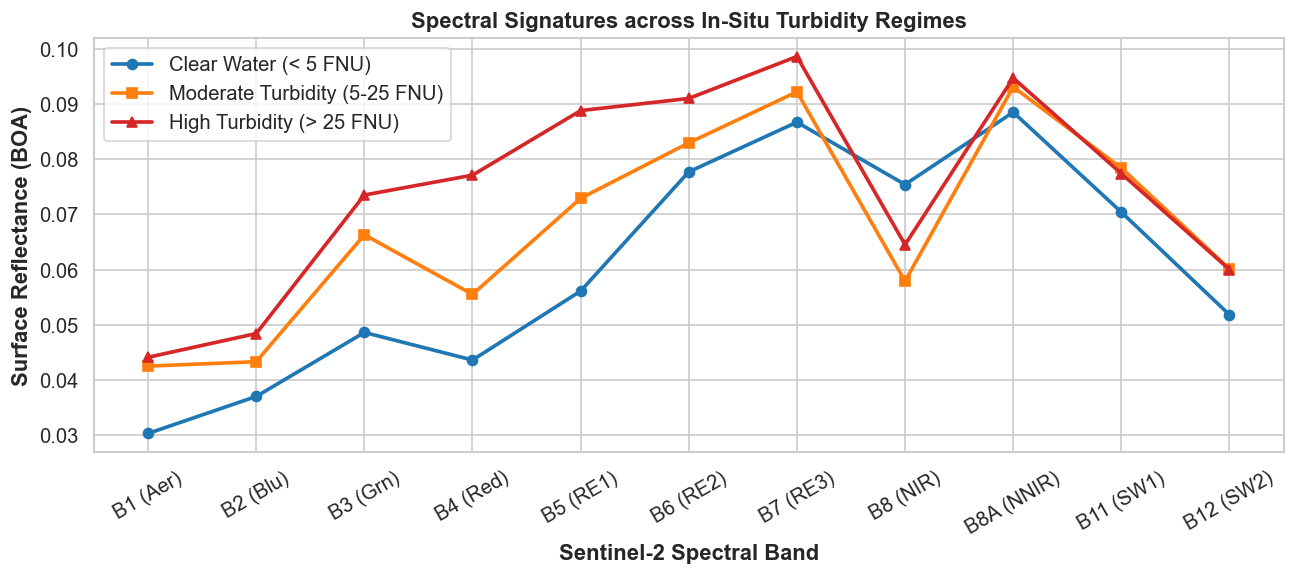

In [4]:
bands = [
    'B01_center_refl', 'B02_center_refl', 'B03_center_refl', 'B04_center_refl',
    'B05_center_refl', 'B06_center_refl', 'B07_center_refl', 'B08_center_refl',
    'B8A_center_refl', 'B11_center_refl', 'B12_center_refl'
]
band_names = ['B1 (Aer)', 'B2 (Blu)', 'B3 (Grn)', 'B4 (Red)', 'B5 (RE1)',
              'B6 (RE2)', 'B7 (RE3)', 'B8 (NIR)', 'B8A (NNIR)', 'B11 (SW1)', 'B12 (SW2)']

sub_turb = df_dl[df_dl['target_type'] == 'turbidity']

low_turb = sub_turb[sub_turb['MeasurementValue'] < 5][bands].median()
med_turb = sub_turb[(sub_turb['MeasurementValue'] >= 5) & (sub_turb['MeasurementValue'] <= 25)][bands].median()
high_turb = sub_turb[sub_turb['MeasurementValue'] > 25][bands].median()

plt.figure(figsize=(11, 5), dpi=120)
x = np.arange(len(bands))
plt.plot(x, low_turb, 'o-', color='#1f77b4', lw=2.2, ms=6, label='Clear Water (< 5 FNU)')
plt.plot(x, med_turb, 's-', color='#ff7f0e', lw=2.2, ms=6, label='Moderate Turbidity (5-25 FNU)')
plt.plot(x, high_turb, '^-', color='#d62728', lw=2.2, ms=6, label='High Turbidity (> 25 FNU)')

plt.xticks(x, band_names, rotation=30)
plt.xlabel('Sentinel-2 Spectral Band', fontweight='bold')
plt.ylabel('Surface Reflectance (BOA)', fontweight='bold')
plt.title('Spectral Signatures across In-Situ Turbidity Regimes', fontweight='bold')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

### Key Remote Sensing Finding:
In turbid water, high concentrations of suspended particulate matter induce strong backscattering in the Near-Infrared ($B8 / B8A$) and Red-Edge ($B5 - B7$) channels. As a result, the reflectance in $B8$ frequently exceeds $B3$ (Green), causing naive $\text{NDWI} = (B3 - B8) / (B3 + B8)$ to drop below zero, falsely categorizing sediment-laden rivers as non-water!

## 4. Basin-Level Distribution & Masking Disagreement

,basin,total_records,dl_water_count,ndwi_water_count,dl_disagreement_count,ndwi_disagreement_count,dl_vs_ndwi_disagree_count,dl_exclusion_rate_%,ndwi_exclusion_rate_%,dl_vs_ndwi_diff_rate_%
0,Delaware,25900,10312,3146,15588,22754,8180,60.19,87.85,31.58
1,Illinois,45169,8434,1804,36735,43365,7924,81.33,96.01,17.54
2,Trinity,24374,14378,15021,9996,9353,3261,41.01,38.37,13.38
3,Upper Colorado,33455,9686,3967,23769,29488,6305,71.05,88.14,18.85
4,Willamette,21102,8387,1997,12715,19105,6944,60.25,90.54,32.91


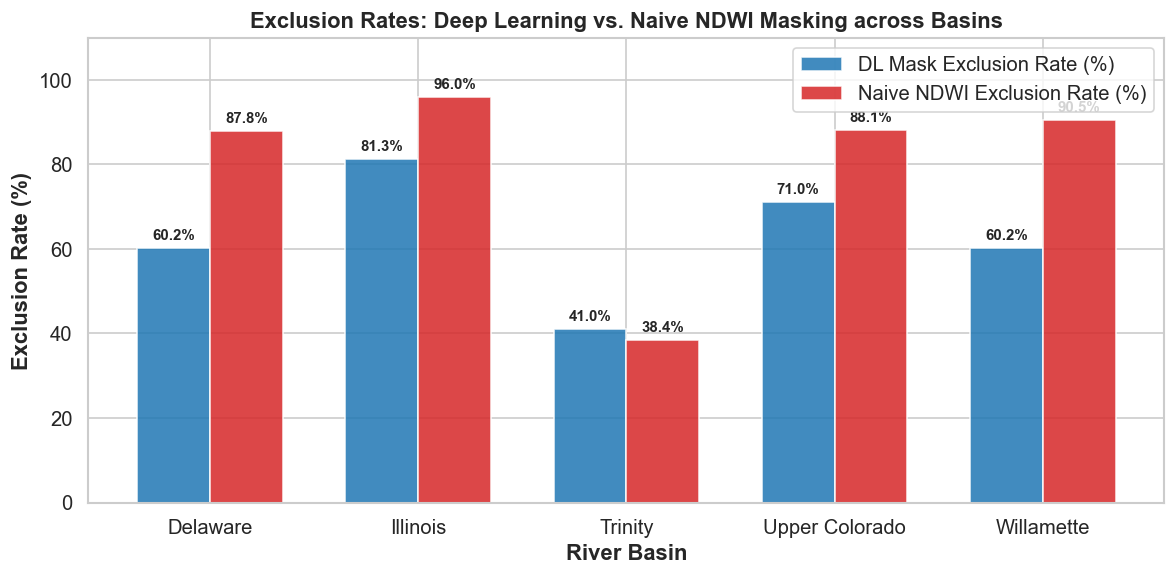

In [5]:
disagreement_path = os.path.join(RESULTS_DIR, "tables", "stage2_disagreement_analysis.csv")
if os.path.exists(disagreement_path):
    df_disagree = pd.read_csv(disagreement_path)
    display(df_disagree)
    
    plt.figure(figsize=(10, 5), dpi=120)
    x = np.arange(len(df_disagree))
    w = 0.35
    plt.bar(x - w/2, df_disagree['dl_exclusion_rate_%'], w, label='DL Mask Exclusion Rate (%)', color='#1f77b4', alpha=0.85)
    plt.bar(x + w/2, df_disagree['ndwi_exclusion_rate_%'], w, label='Naive NDWI Exclusion Rate (%)', color='#d62728', alpha=0.85)
    plt.title('Exclusion Rates: Deep Learning vs. Naive NDWI Masking across Basins', fontweight='bold')
    plt.ylabel('Exclusion Rate (%)', fontweight='bold')
    plt.xlabel('River Basin', fontweight='bold')
    plt.xticks(x, df_disagree['basin'])
    plt.ylim(0, 110)
    for i in range(len(df_disagree)):
        plt.text(x[i] - w/2, df_disagree['dl_exclusion_rate_%'].iloc[i] + 2, f"{df_disagree['dl_exclusion_rate_%'].iloc[i]:.1f}%", ha='center', fontsize=9, fontweight='bold')
        plt.text(x[i] + w/2, df_disagree['ndwi_exclusion_rate_%'].iloc[i] + 2, f"{df_disagree['ndwi_exclusion_rate_%'].iloc[i]:.1f}%", ha='center', fontsize=9, fontweight='bold')
    plt.legend()
    plt.tight_layout()
    plt.show()

## 5. Summary of Downstream Validation

As detailed in our journal report and Experiment A (`src/evaluation/ablation.py`):
- Under the **DL-masked condition**, the downstream Turbidity retrieval model achieved $R^2 = 0.2904$, compared to $R^2 = 0.2047$ under naive NDWI masking (**+41.8% relative improvement**).
- Paired statistical testing confirmed this improvement is highly statistically significant:
  - **Paired t-test**: $p = 1.67 \times 10^{-14}$
  - **Wilcoxon signed-rank test**: $p = 3.64 \times 10^{-7}$

This confirms the hypothesis that high-capacity multi-band deep learning water extraction provides a cleaner, noise-free aquatic spectrum foundation for machine learning water quality inversion.